# Fragment embedding UMAP (Figure 3e-f)
Reads tables from `../data/` and writes figures to `../output/`. Source notebook is listed in `../../NOTEBOOK_PROVENANCE.tsv`.

In [1]:
from pathlib import Path
import sys

nb_dir = Path.cwd()
if (nb_dir.parent / "data").exists():
    MOD_DIR = nb_dir.parent
else:
    MOD_DIR = nb_dir
DATA = MOD_DIR / "data"
OUT  = MOD_DIR / "output"
OUT.mkdir(exist_ok=True)

_p = nb_dir
while _p != _p.parent and not (_p / "src" / "leaf1figures").exists():
    _p = _p.parent
sys.path.insert(0, str(_p / "src"))
from leaf1figures.style import savefig, set_paper_style
set_paper_style()

print("DATA:", DATA)
print("OUT :", OUT)

DATA: /home/hamedh/projects/fragmentomics/multi_modal_fragments/bert_window_embedding/draft/leaf-1-figures/scatac/data
OUT : /home/hamedh/projects/fragmentomics/multi_modal_fragments/bert_window_embedding/draft/leaf-1-figures/scatac/output


In [2]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.spines.top": False, "axes.spines.right": False,
    "font.family": "sans-serif",
    "font.sans-serif": ["Helvetica", "Arial", "DejaVu Sans"],
    "pdf.fonttype": 42, "ps.fonttype": 42,
    "font.size": 10, "savefig.dpi": 300, "savefig.bbox": "tight",
})

TARGET_TF    = "FOXA2"
TARGET_REGEX = "[AT]GTAAACA"

comp_names = json.loads((DATA / "comp_names.json").read_text())
frag_label = json.loads((DATA / "frag_labels.json").read_text())
embedding  = np.load(DATA / "umap_embedding.npy")

print(f"Embedding    : {embedding.shape}")
print(f"Fragments    : {embedding.shape[0]:,}")
print(f"Cell types   : {len(set(frag_label))}")

Embedding    : (51000, 2)
Fragments    : 51,000
Cell types   : 102


Top-10 cell type UMAP
Fragments colored by the 10 cell-type comparisons with highest LEAF-1 AUC. Grey = other cell types.

Top-10 cell types: ['Hepatocyte_vs_all', 'Pancreatic_Beta_Cell_2_vs_all', 'Type_II_Skeletal_Myocyte_vs_all', 'Macrophage_General_Alveolar_vs_all', 'Parietal_Cell_vs_all', 'Thyroid_Follicular_Cell_vs_all', 'Pancreatic_Alpha_Cell_2_vs_all', 'Keratinocyte_2_vs_all', 'Atrial_Cardiomyocyte_vs_all', 'Cortical_Epithelial-like_vs_all']
Top-10 fragments: 5,000 / 51,000
saved: /home/hamedh/projects/fragmentomics/multi_modal_fragments/bert_window_embedding/draft/leaf-1-figures/scatac/output/scatac_foxa2_umap_top10_celltype.pdf
saved: /home/hamedh/projects/fragmentomics/multi_modal_fragments/bert_window_embedding/draft/leaf-1-figures/scatac/output/scatac_foxa2_umap_top10_celltype.png
saved: /home/hamedh/projects/fragmentomics/multi_modal_fragments/bert_window_embedding/draft/leaf-1-figures/scatac/output/scatac_foxa2_umap_top10_celltype.svg
saved: /home/hamedh/projects/fragmentomics/multi_modal_fragments/bert_window_embedding/draft/leaf-1-figures/scatac/output/scatac_foxa2_umap_top10_celltype.tsv


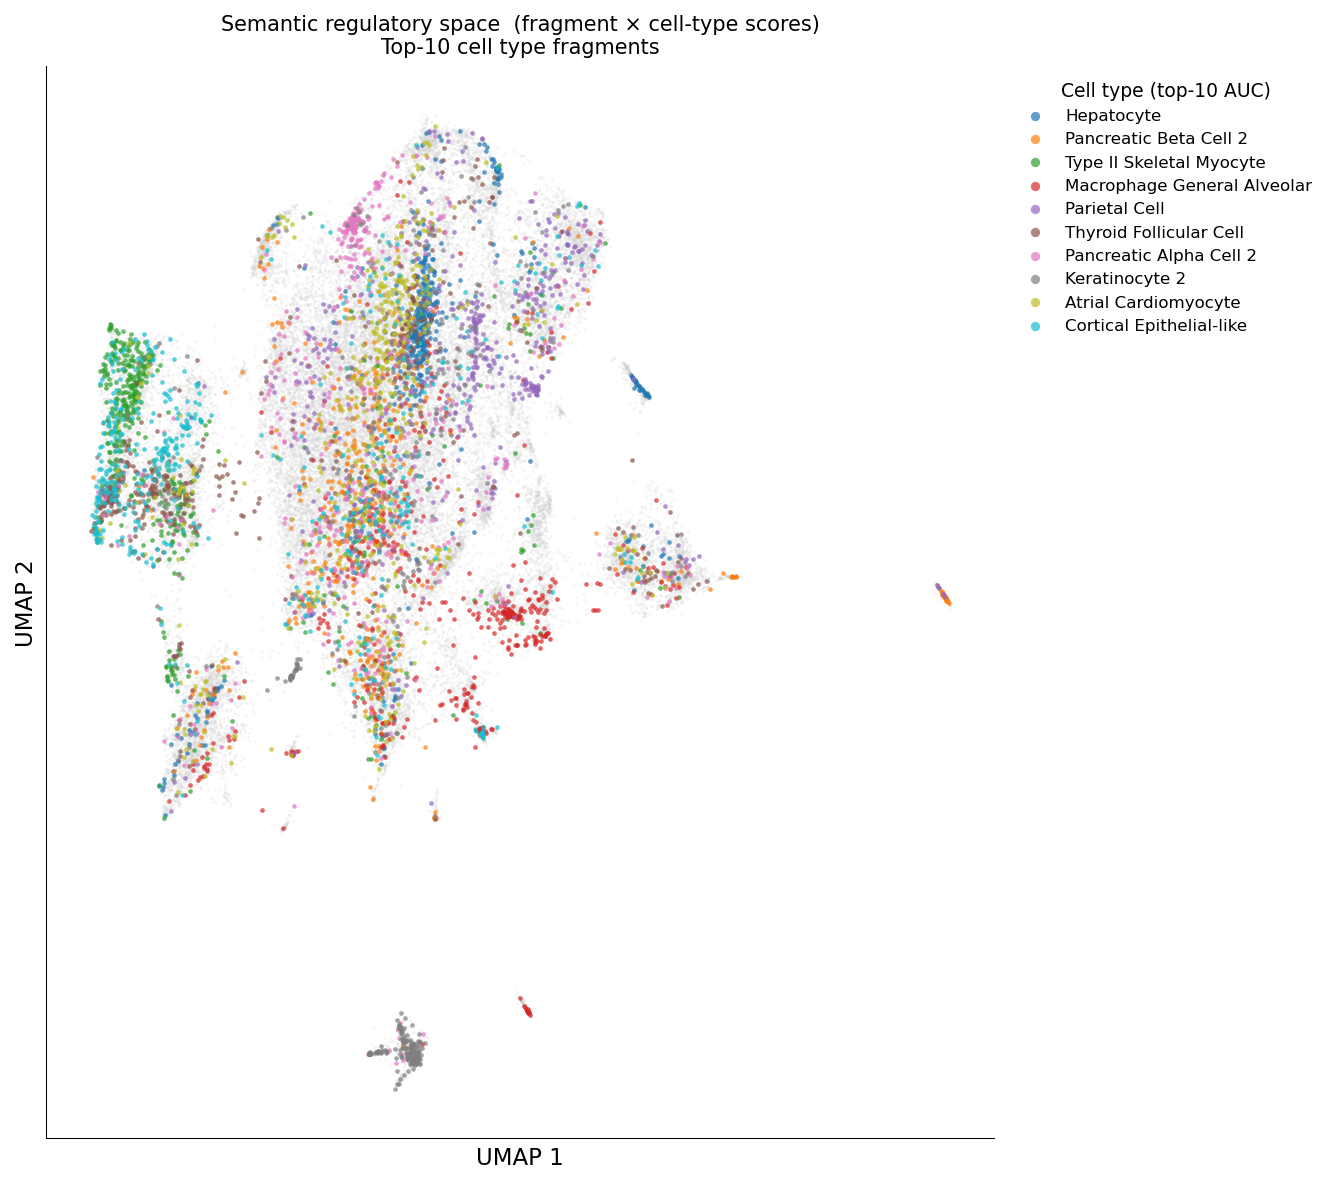

In [3]:
top10_comps = [
    line.strip()
    for line in (DATA / "target_auc_top10.txt").read_text().splitlines()
    if line.strip()
]
print(f"Top-10 cell types: {top10_comps}")

palette10   = plt.get_cmap("tab10").colors
top10_color = {comp: palette10[i] for i, comp in enumerate(top10_comps)}
is_top10    = np.array([comp_names[label_idx] in top10_color for label_idx in frag_label])
print(f"Top-10 fragments: {is_top10.sum():,} / {len(frag_label):,}")

fig, ax = plt.subplots(figsize=(9, 8))
ax.scatter(
    embedding[~is_top10, 0], embedding[~is_top10, 1],
    c="#d0d0d0", s=2, alpha=0.20, linewidths=0, rasterized=True, zorder=1,
)
for comp in top10_comps:
    mask  = np.array([comp_names[label_idx] == comp for label_idx in frag_label])
    label = comp.replace("_vs_all", "").replace("_", " ")
    ax.scatter(
        embedding[mask, 0], embedding[mask, 1],
        c=[top10_color[comp]], s=5, alpha=0.70, linewidths=0,
        label=label, rasterized=True, zorder=2,
    )
ax.legend(
    title="Cell type (top-10 AUC)",
    bbox_to_anchor=(1.01, 1), loc="upper left",
    fontsize=8, title_fontsize=9, frameon=False, markerscale=2,
)
ax.set_xlabel("UMAP 1", fontsize=11)
ax.set_ylabel("UMAP 2", fontsize=11)
ax.set_title(
    "Semantic regulatory space  (fragment × cell-type scores)\nTop-10 cell type fragments",
    fontsize=10,
)
ax.set_xticks([]); ax.set_yticks([])
fig.tight_layout()
savefig(fig, OUT, "scatac_foxa2_umap_top10_celltype", data=(pd.DataFrame({'umap1':embedding[:,0],'umap2':embedding[:,1],'cell_type':[comp_names[i] for i in frag_label],'is_top10':is_top10})))
plt.show()

FOXA2 motif presence on UMAP

FOXA2 coverage: 51.5%  (2,523 present, 23,765 absent, 24,712 not found)
saved: /home/hamedh/projects/fragmentomics/multi_modal_fragments/bert_window_embedding/draft/leaf-1-figures/scatac/output/scatac_foxa2_umap_binary.pdf
saved: /home/hamedh/projects/fragmentomics/multi_modal_fragments/bert_window_embedding/draft/leaf-1-figures/scatac/output/scatac_foxa2_umap_binary.png
saved: /home/hamedh/projects/fragmentomics/multi_modal_fragments/bert_window_embedding/draft/leaf-1-figures/scatac/output/scatac_foxa2_umap_binary.svg
saved: /home/hamedh/projects/fragmentomics/multi_modal_fragments/bert_window_embedding/draft/leaf-1-figures/scatac/output/scatac_foxa2_umap_binary.tsv


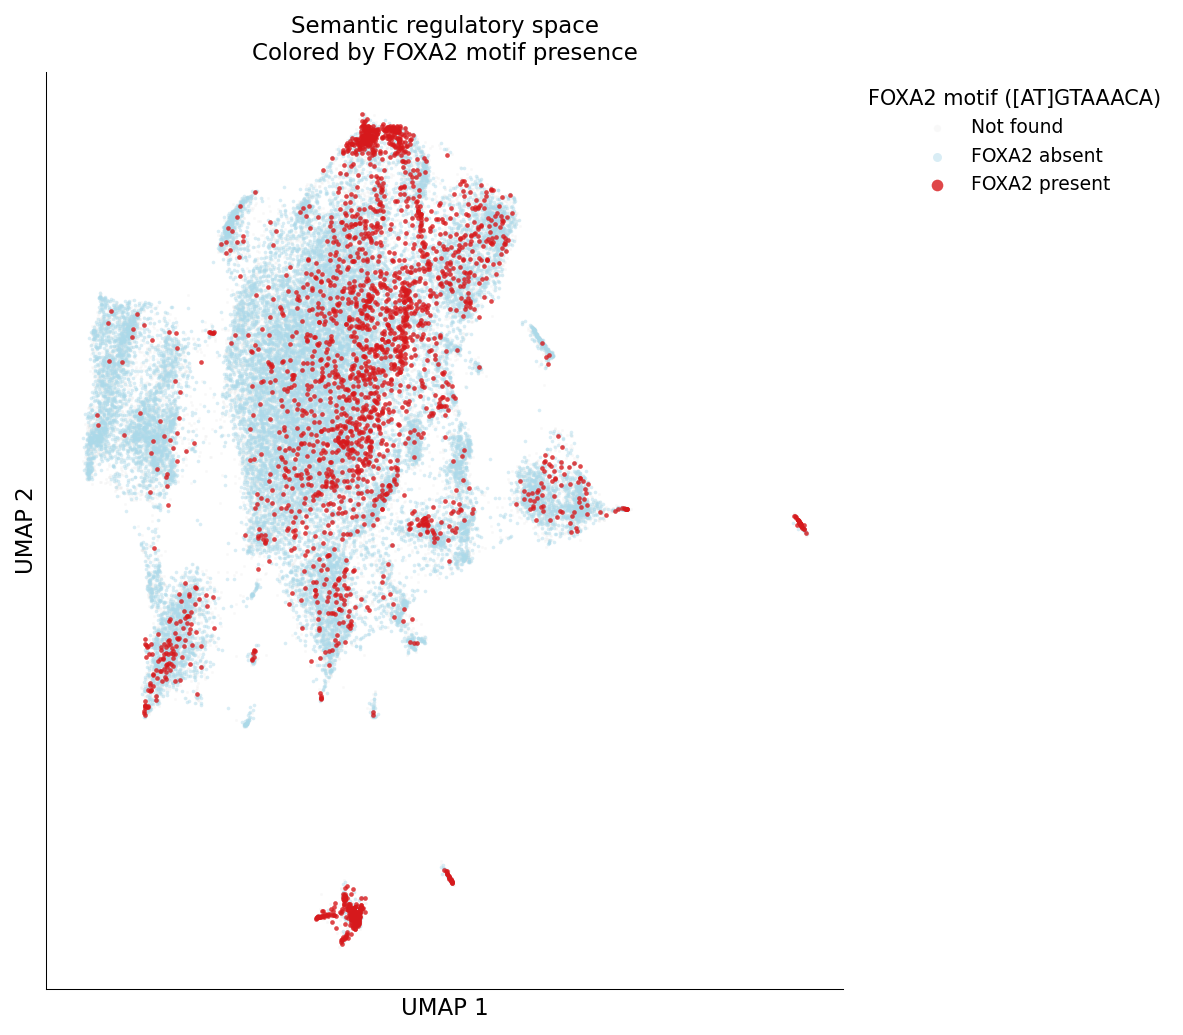

In [4]:
foxa2_vals = pd.read_csv(DATA / "foxa2_map.csv")["foxa2"].values.astype("int8")

if len(foxa2_vals) != embedding.shape[0]:
    raise ValueError(
        f"FOXA2 map length ({len(foxa2_vals)}) != embedding rows ({embedding.shape[0]})"
    )

n_pos, n_neg, n_miss = (foxa2_vals == 1).sum(), (foxa2_vals == 0).sum(), (foxa2_vals == -1).sum()
coverage = (n_pos + n_neg) / len(foxa2_vals)
print(f"FOXA2 coverage: {coverage:.1%}  ({n_pos:,} present, {n_neg:,} absent, {n_miss:,} not found)")

FOXA2_POS_COLOR = "#d7191c"
FOXA2_NEG_COLOR = "#abd9e9"
MISSING_COLOR   = "#e0e0e0"

mask_pos = foxa2_vals == 1
mask_neg = foxa2_vals == 0
mask_mis = foxa2_vals == -1

fig, ax = plt.subplots(figsize=(8, 7))
ax.scatter(embedding[mask_mis, 0], embedding[mask_mis, 1],
           c=MISSING_COLOR, s=2, alpha=0.20, linewidths=0,
           rasterized=True, zorder=1, label="Not found")
ax.scatter(embedding[mask_neg, 0], embedding[mask_neg, 1],
           c=FOXA2_NEG_COLOR, s=3, alpha=0.45, linewidths=0,
           rasterized=True, zorder=2, label="FOXA2 absent")
ax.scatter(embedding[mask_pos, 0], embedding[mask_pos, 1],
           c=FOXA2_POS_COLOR, s=5, alpha=0.80, linewidths=0,
           rasterized=True, zorder=3, label="FOXA2 present")
ax.legend(
    title=f"{TARGET_TF} motif ({TARGET_REGEX})",
    bbox_to_anchor=(1.01, 1), loc="upper left",
    fontsize=9, title_fontsize=10, frameon=False, markerscale=2.5,
)
ax.set_xlabel("UMAP 1", fontsize=11)
ax.set_ylabel("UMAP 2", fontsize=11)
ax.set_title(
    f"Semantic regulatory space\nColored by {TARGET_TF} motif presence",
    fontsize=11,
)
ax.set_xticks([]); ax.set_yticks([])
fig.tight_layout()
savefig(fig, OUT, f"scatac_foxa2_umap_binary", data=(pd.DataFrame({'umap1':embedding[:,0],'umap2':embedding[:,1],'foxa2_motif':foxa2_vals})))
plt.show()